# Part 3: Recommendation with Embeddings
## Gym Sales Training Simulator - Conversation Recommender

A junior salesperson describes, in free text, the type of customer they want to practice on.
The system retrieves the **Top-3 most similar real sales conversations** from our dataset -
including how each conversation ended (SUCCESS / FAILURE) - so the trainee learns from what
actually worked and what didn't.

**Pipeline:** `USER QUERY (text) -> embedding model -> FAISS similarity search -> Top-3 conversations + outcome stats`

Steps in this notebook:
1. Load the dataset directly from our HF dataset repo
2. Build one "conversation document" per dialogue (pre-decision customer turns + demographic context)
3. Compare 3 embedding models - quantitative (Persona Precision@3 + a leave-one-out mood metric) + qualitative evaluation
4. Embed all conversations with the winning model, index with FAISS
5. Recommend Top-3 similar conversations with outcome summary
6. Publish the embeddings to the HF repo so the Part 5 app can load them

In [2]:
!pip install -q sentence-transformers faiss-cpu pandas numpy huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 130.5 MB/s eta 0:00:00


In [3]:
import pandas as pd

# Read directly from our HF dataset repo (Part 5 constraint)
DATASET_URL = "https://huggingface.co/datasets/elg4/Gym_Salesman_Dataset/resolve/main/gym_sales_dataset.jsonl"

df = pd.read_json(DATASET_URL, lines=True)
print(f"Total conversations: {len(df)}")
df.head(3)

Total conversations: 11997


,sample_id,outcome,dialogue,decision_turn_index,persona,demographic,mood,gym,price,n_turns
0,0,SUCCESS,"[{'role': 'sales', 'text': 'Hi there! Welcome ...",7,Ariel - Impulsive Commitment-Phobe,"Male, mid-20s - Recently discharged, chasing t...",Defensive about being asked to commit,The Forge Gym,₪179/month,8
1,1,FAILURE,"[{'role': 'sales', 'text': 'Hi there! Welcome ...",7,Ariel - Impulsive Commitment-Phobe,"Male, 30s - Serial hobbyist with a garage full...",Defensive about being asked to commit,The Forge Gym,₪219/month,8
2,2,FAILURE,"[{'role': 'sales', 'text': 'So, you're looking...",7,Yuval - Procrastinating CS Student,"Male, early 20s - Economics student juggling a...","Distracted, mentally still on tomorrow's deadline",Vitality Health Club,₪219/month,8


## Building the "Conversation Document"

Each row is one full sales conversation. We embed **the customer's turns up to (not including)
the decision turn**, prefixed with the customer's demographic description. Three deliberate choices:

1. **No outcome leakage** - the final customer turn states the decision ("let's sign up" /
   "I need more time"). Including it would make vectors cluster by outcome rather than by
   customer situation, and would contradict the leakage audit we published in the dataset card
   (which excluded the decision turn). We slice at `decision_turn_index` so the outcome stays
   what the system *reveals*, not part of the search key.
2. **No archetype labels** - the `persona` and `mood` label strings are excluded from the
   document. Embedding them would turn our evaluation into string matching between a query and
   its own label ("Yuval - Procrastinating CS Student" vs "a busy student..."), inflating the
   metrics without proving the model understands the conversation. `demographic` is kept: it
   describes the customer (age, occupation) rather than naming the archetype, and trainee
   queries legitimately reference it ("a student", "a retiree").
3. **Customer turns only, semantic alignment** - the query describes a *customer*; the
   customer's own words (their objections) express it. The rep's pitch is near-identical across
   conversations and would add noise. This also keeps documents within the 256-token limit of
   sentence-transformer models (an 8-turn dialogue would be silently truncated).

In [4]:
def build_conversation_document(row):
    """Demographic context + what the customer said BEFORE stating a decision.

    Slicing at decision_turn_index keeps the outcome out of the embedding;
    persona/mood label strings are excluded so retrieval metrics measure
    understanding of conversation content, not string matching.
    """
    turns = row["dialogue"][: row["decision_turn_index"]]
    customer_turns = " ".join(t["text"] for t in turns if t["role"] == "customer")
    context = f"{row['demographic']}."
    return f"{context} Customer says: {customer_turns}"

df["conversation_document"] = df.apply(build_conversation_document, axis=1)

print(df.loc[0, "conversation_document"][:600])

Male, mid-20s - Recently discharged, chasing the next thing to be excited about. Customer says: Thanks for the details! That really hits close to home with me – every gym I've been to always makes canceling a pain, with all those callbacks and paperwork. That sounds like a reasonable policy – thanks for explaining. Honestly, though, I still worry that after a month, I'll find myself checking my watch and thinking about other things rather than sticking with it. That 7-day free trial and the first month being refundable certainly gives me peace of mind. But I’m still concerned about getting bor


## Embedding Model Comparison

Three candidates:

| Model | Dim | Params | Notes |
|---|---|---|---|
| `all-MiniLM-L6-v2` | 384 | 22M | small & fast, general-purpose |
| `all-mpnet-base-v2` | 768 | 109M | larger, stronger on STS benchmarks |
| `BAAI/bge-small-en-v1.5` | 384 | 33M | retrieval-tuned, requires a query prefix |

**Evaluation protocol.** Raw cosine scores are NOT comparable across models - each model
has its own score distribution, so a higher score does not mean a better match.
We therefore evaluate with:
1. **Persona Precision@3** - test queries with a known target persona; the fraction of
   top-3 retrieved conversations whose persona matches the target. Since persona labels
   are NOT in the encoded text, a hit means the model inferred the customer type from
   the demographic and the conversation content.
2. **Qualitative sanity check** - reading the actual retrievals (next cell).
3. **Practical cost** - model size and encoding time over the full corpus.
4. **Leave-one-out mood agreement@3** - a finer-grained metric (20 mood classes,
   500 sampled conversations). Mood labels are also NOT in the encoded text, so this
   measures whether the model picks up emotional tone from the customer's words alone.
   It is the cleanest metric in principle - but see the selection cell below: in practice
   it turned out to sit at chance level for all three models, and we report that honestly
   rather than reading a ranking into noise.

In [5]:
import time
import numpy as np
from sentence_transformers import SentenceTransformer

candidate_models = [
    "sentence-transformers/all-MiniLM-L6-v2",
    "sentence-transformers/all-mpnet-base-v2",
    "BAAI/bge-small-en-v1.5",
]

# BGE was trained to see queries with this instruction; the other models need none.
# Kept as a dict so serving-time code uses the exact same prefix as evaluation.
QUERY_PREFIXES = {
    "BAAI/bge-small-en-v1.5": "Represent this sentence for searching relevant passages: ",
}

# Each query targets one known persona -> lets us measure retrieval precision objectively
test_queries = {
    "I want to practice on a busy student who is afraid of long commitments":
        "Yuval - Procrastinating CS Student",
    "A price-sensitive customer who compares offers and negotiates every shekel":
        "Omer - Analytical Bargain Hunter",
    "An anxious beginner who has never set foot in a gym and fears the equipment":
        "Noam - Anxious First-Timer",
    "Someone who gets excited quickly, signs up impulsively, then quits after a month":
        "Ariel - Impulsive Commitment-Phobe",
    "A distracted university student with a heavy course load and no free time":
        "Yuval - Procrastinating CS Student",
}

documents = df["conversation_document"].tolist()
personas = df["persona"].to_numpy()

comparison_rows, qualitative = [], {}
corpus_embeddings = {}  # cache per model -> the winner's vectors are reused later, no re-encoding

for model_name in candidate_models:
    m = SentenceTransformer(model_name)
    prefix = QUERY_PREFIXES.get(model_name, "")

    t0 = time.time()
    emb = m.encode(documents, convert_to_numpy=True,
                   normalize_embeddings=True, show_progress_bar=True)
    encode_time = time.time() - t0
    corpus_embeddings[model_name] = emb
    size_mb = sum(p.numel() * p.element_size() for p in m.parameters()) / 1024**2

    precisions = []
    for query, target_persona in test_queries.items():
        q_emb = m.encode([prefix + query], convert_to_numpy=True, normalize_embeddings=True)
        sims = (emb @ q_emb.T).flatten()
        top3 = np.argsort(-sims)[:3]
        precisions.append((personas[top3] == target_persona).mean())
        qualitative[(model_name, query)] = [
            (personas[i], df.iloc[i]["mood"], df.iloc[i]["outcome"], round(float(sims[i]), 3))
            for i in top3
        ]

    comparison_rows.append({
        "model": model_name,
        "persona_precision@3": round(np.mean(precisions), 3),
        "dim": emb.shape[1],
        "size_mb": round(size_mb, 1),
        "encode_time_s": round(encode_time, 1),
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values("persona_precision@3", ascending=False)
comparison_df

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (33 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/375 [00:00<?, ?it/s]

,model,persona_precision@3,dim,size_mb,encode_time_s
2,BAAI/bge-small-en-v1.5,1.000,384,127.3,9.6
1,sentence-transformers/all-mpnet-base-v2,0.933,768,417.7,24.0
0,sentence-transformers/all-MiniLM-L6-v2,0.733,384,86.6,7.4


In [6]:
# Qualitative sanity check: read what each model actually retrieved
for query, target in test_queries.items():
    print("=" * 95)
    print(f'QUERY: "{query}"')
    print(f"TARGET PERSONA: {target}")
    for model_name in candidate_models:
        print(f"\n  [{model_name}]")
        for persona, mood, outcome, score in qualitative[(model_name, query)]:
            flag = " OK " if persona == target else "MISS"
            print(f"    [{flag}] {persona:38s} | {mood:52s} | {outcome:7s} | {score}")
    print()

QUERY: "I want to practice on a busy student who is afraid of long commitments"
TARGET PERSONA: Yuval - Procrastinating CS Student

  [sentence-transformers/all-MiniLM-L6-v2]
    [ OK ] Yuval - Procrastinating CS Student     | Hesitant, half-expecting to talk himself out of it   | FAILURE | 0.656
    [ OK ] Yuval - Procrastinating CS Student     | Hesitant, half-expecting to talk himself out of it   | SUCCESS | 0.636
    [ OK ] Yuval - Procrastinating CS Student     | Cynical, has heard every gym pitch before            | SUCCESS | 0.609

  [sentence-transformers/all-mpnet-base-v2]
    [ OK ] Yuval - Procrastinating CS Student     | Guarded, allergic to being sold to                   | FAILURE | 0.538
    [ OK ] Yuval - Procrastinating CS Student     | Hesitant, half-expecting to talk himself out of it   | FAILURE | 0.518
    [ OK ] Yuval - Procrastinating CS Student     | Tired but genuinely hoping this time is different    | FAILURE | 0.507

  [BAAI/bge-small-en-v1.5]
    [ OK ] Yuv

In [7]:
# Second metric at MOOD granularity (20 classes instead of 4).
# Leave-one-out retrieval: 500 sampled conversations each query the rest of the
# corpus; we measure how often the top-3 neighbors share the query's persona/mood.
# Mood labels are NOT in the encoded documents, so agreement here means the model
# inferred emotional tone from the customer's words alone.
# Runs entirely on the cached corpus embeddings - no re-encoding.

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(df), size=500, replace=False)
moods = df["mood"].to_numpy()

tie_rows = []
for model_name in candidate_models:
    emb = corpus_embeddings[model_name]
    sims_matrix = emb[sample_idx] @ emb.T
    sims_matrix[np.arange(len(sample_idx)), sample_idx] = -np.inf  # exclude self-match
    top3 = np.argsort(-sims_matrix, axis=1)[:, :3]

    tie_rows.append({
        "model": model_name,
        "LOO_persona_agreement@3": round((personas[top3] == personas[sample_idx][:, None]).mean(), 3),
        "LOO_mood_agreement@3": round((moods[top3] == moods[sample_idx][:, None]).mean(), 3),
    })

tiebreak_df = pd.DataFrame(tie_rows).sort_values("LOO_mood_agreement@3", ascending=False)
tiebreak_df

,model,LOO_persona_agreement@3,LOO_mood_agreement@3
0,sentence-transformers/all-MiniLM-L6-v2,0.997,0.221
2,BAAI/bge-small-en-v1.5,0.992,0.209
1,sentence-transformers/all-mpnet-base-v2,0.996,0.197


### Model Selection: `BAAI/bge-small-en-v1.5`

#### Round 1 - Persona Precision@3 (the decisive metric)

Five free-text queries, each written to target one known persona; we measure the fraction of
the top-3 retrieved conversations whose persona matches.

| Model | Persona Precision@3 | Dim | Size (MB) | Encode time (11,997 docs) |
|---|---|---|---|---|
| **BAAI/bge-small-en-v1.5** | **1.000** | 384 | **127.3** | **9.6s** |
| all-mpnet-base-v2 | 0.933 | 768 | 417.7 | 24.0s |
| all-MiniLM-L6-v2 | 0.733 | 384 | 86.6 | 7.4s |

**This spread is itself a result.** In an earlier iteration the `persona` label string was part
of the encoded document, and all three models scored a perfect 1.00 - the metric was measuring
string overlap between a query and its own label, and could not discriminate between models.
After removing the label strings and the decision turn, the identical protocol produces a
0.733-1.000 spread, so these numbers reflect genuine semantic retrieval from the customer's
words and demographic alone.

#### Round 2 - the leave-one-out metrics did not discriminate

We had planned the leave-one-out evaluation as a finer-grained tie-breaker. It did not work
as intended, and we report that rather than over-reading it:

| Model | LOO persona agreement@3 | LOO mood agreement@3 |
|---|---|---|
| all-MiniLM-L6-v2 | 0.997 | 0.221 |
| all-mpnet-base-v2 | 0.996 | 0.197 |
| BAAI/bge-small-en-v1.5 | 0.992 | 0.209 |

- **Persona agreement saturates at ~0.99** for all three. A conversation's nearest neighbours
  are almost always the same persona, because personas differ in *what the customer talks
  about*. The metric has no headroom left.
- **Mood agreement sits at chance.** Each mood belongs to exactly one persona (5 moods per
  persona, 20 total, no overlap). Given that the retrieved neighbour is the same persona
  ~99% of the time, picking uniformly among that persona's 5 moods yields an expected
  agreement of **0.200**. The observed values - 0.197, 0.209, 0.221 - straddle that baseline.
  None of the models resolves mood beyond chance, so the 0.221-vs-0.209 ordering is noise and
  we do not use it to rank models.

This is a real limitation of the metric, not of the recommender: mood in our dataset is a
generation-time attribute that surfaces as tone rather than as distinct content, so
sentence-level retrieval has little to grip. It is documented here as a known result.

#### Round 3 - qualitative check

Reading the actual retrievals confirms the Round 1 ranking. On the query *"an anxious beginner
who has never set foot in a gym and fears the equipment"*, MiniLM returned three **Ariel**
conversations (impulsive commitment-phobe) - a complete miss on the customer's emotional
register. BGE and mpnet both returned **Noam** correctly. On the price-sensitive query, MiniLM
and mpnet each returned one wrong persona; BGE returned three correct ones.

#### Decision

We select **`BAAI/bge-small-en-v1.5`**:

- **Highest retrieval accuracy** on the metric that mirrors real usage (1.000 vs 0.933 vs 0.733),
  and the only model with no qualitative misses.
- **Cheapest to run of the accurate models**: fastest full-corpus encode (9.6s) and 3.3x smaller
  than mpnet (127MB vs 418MB), while beating it on accuracy - there is no accuracy/cost trade-off
  to make here.
- **End-to-end query latency of 14 ms**, which comfortably supports live interaction in the
  Part 5 application.
- Its one operational cost, a required query-instruction prefix, is stored inside the embeddings
  file and applied automatically at serving time, so evaluation and production use an identical
  prefix and cannot drift apart.

MiniLM is 40MB smaller and 2s faster, which does not compensate for retrieving the wrong customer
type on a third of the queries. mpnet costs 3.3x the memory and 2.5x the encode time for lower
accuracy.

In [8]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [9]:
import pickle, os

WINNING_MODEL = "BAAI/bge-small-en-v1.5"  # selected in the comparison above

model = SentenceTransformer(WINNING_MODEL)
query_prefix = QUERY_PREFIXES.get(WINNING_MODEL, "")
embeddings = corpus_embeddings[WINNING_MODEL]  # already computed in the comparison

EMBEDDINGS_PATH = "/content/drive/MyDrive/runi/data science/final project/gym_conversation_embeddings.pkl"
os.makedirs(os.path.dirname(EMBEDDINGS_PATH), exist_ok=True)   # create the folder if missing

# The pickle holds ONLY what cannot be re-read from the HF dataset repo:
# the vectors, their row alignment (sample_id), the model name, and its query prefix.
# The app (Part 5) reads the conversations themselves directly from the HF repo,
# as required, and aligns them to these vectors via sample_id.
with open(EMBEDDINGS_PATH, "wb") as f:
    pickle.dump({
        "model_name": WINNING_MODEL,
        "query_prefix": query_prefix,
        "embeddings": embeddings,
        "sample_ids": df["sample_id"].to_numpy(),
    }, f)

print(f"Saved {embeddings.shape} embeddings to {EMBEDDINGS_PATH}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Saved (11997, 384) embeddings to /content/drive/MyDrive/runi/data science/final project/gym_conversation_embeddings.pkl


In [10]:
import faiss

index = faiss.IndexFlatIP(embeddings.shape[1])  # inner product == cosine (vectors are normalized)
index.add(embeddings)
print(f"FAISS index ready: {index.ntotal} vectors, dim={index.d}")

FAISS index ready: 11997 vectors, dim=384


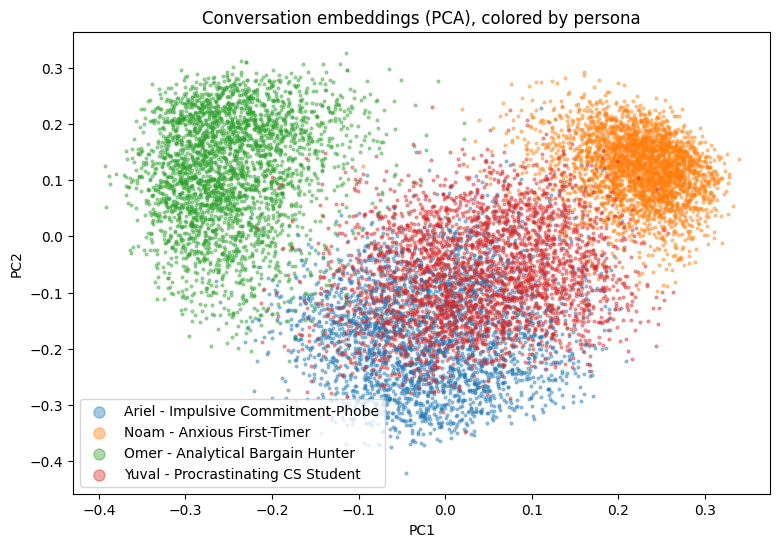

In [11]:
# Visualize the embedding space: project all conversation embeddings to 2D,
# colored by persona (which is NOT in the encoded text - any visible clustering
# reflects what the model inferred from demographics and conversation content).
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

coords = PCA(n_components=2, random_state=42).fit_transform(embeddings)

plt.figure(figsize=(9, 6))
for persona in sorted(df["persona"].unique()):
    mask = (df["persona"] == persona).to_numpy()
    plt.scatter(coords[mask, 0], coords[mask, 1], s=4, alpha=0.4, label=persona)
plt.legend(markerscale=4)
plt.title("Conversation embeddings (PCA), colored by persona")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [12]:
def recommend_conversations(query, top_k=3, candidate_pool=50):
    """
    Free-text customer description -> top_k most similar real conversations.

    Results are deduplicated by customer identity (persona+demographic+mood):
    the same archetype may appear more than once (that's informative - different
    conversations, different outcomes), but not the exact same customer twice.
    """
    q_emb = model.encode([query_prefix + query], convert_to_numpy=True,
                         normalize_embeddings=True)
    scores, indices = index.search(q_emb, candidate_pool)

    picked, seen_customers = [], set()
    for score, idx in zip(scores[0], indices[0]):
        row = df.iloc[idx]
        customer_id = (row["persona"], row["demographic"], row["mood"])
        if customer_id in seen_customers:
            continue
        picked.append((idx, float(score)))
        seen_customers.add(customer_id)
        if len(picked) == top_k:
            break

    results = df.iloc[[i for i, _ in picked]].copy()
    results["similarity_score"] = [s for _, s in picked]
    return results

In [13]:
def print_recommendations(query, results):
    """Top-k similar conversations, each with its profile, outcome, and key quotes."""
    print("=" * 80)
    print(f'SALESPERSON QUERY: "{query}"')
    print("=" * 80)

    n_success = (results["outcome"] == "SUCCESS").sum()
    print(f"\nOutcome summary: {n_success} SUCCESS / {len(results) - n_success} FAILURE "
          f"across {len(results)} similar conversations\n")

    for rank, (_, row) in enumerate(results.iterrows(), 1):
        customer_turns = [t["text"] for t in row["dialogue"] if t["role"] == "customer"]
        print(f"#{rank} | score {row['similarity_score']:.3f} | outcome: {row['outcome']}")
        print(f"    Persona       : {row['persona']}")
        print(f"    Demographic   : {row['demographic']}")
        print(f"    Mood          : {row['mood']}")
        print(f"    Gym / Price   : {row['gym']} / {row['price']}")
        print(f'    First objection : "{customer_turns[0][:150]}"')
        print(f'    Decision quote  : "{customer_turns[-1][:150]}"')
        print()

In [14]:
# End-to-end sanity check of the full recommender
for q in [
    "I want to practice on a busy student who is afraid of long commitments",
    "A tough negotiator who thinks the membership is overpriced",
    "A shy first-timer embarrassed to ask basic questions",
]:
    results = recommend_conversations(q)
    print_recommendations(q, results)

SALESPERSON QUERY: "I want to practice on a busy student who is afraid of long commitments"

Outcome summary: 0 SUCCESS / 3 FAILURE across 3 similar conversations

#1 | score 0.786 | outcome: FAILURE
    Persona       : Yuval - Procrastinating CS Student
    Demographic   : Male, early 20s - Economics student juggling a heavy and stressful course load
    Mood          : Cynical, has heard every gym pitch before
    Gym / Price   : Vitality Health Club / ₪299/month
    First objection : "That sounds like a great idea. But even with a trial pass, I'm worried about knowing what to do once I'm there; I might just stand around aimlessly, w"
    Decision quote  : "Thanks for all the information, but I think I need some more time to think about it. Maybe in a few weeks when my schedule is a bit clearer."

#2 | score 0.756 | outcome: FAILURE
    Persona       : Yuval - Procrastinating CS Student
    Demographic   : Male, early 20s - Computer science student juggling a heavy course load
    Mo

In [15]:
# Measure serving latency: supports the "real-time demo" claim in the model selection.
import time

_ = recommend_conversations("warmup query")  # exclude one-time warmup from timing

t0 = time.time()
_ = recommend_conversations("A skeptical customer comparing three gyms")
latency_ms = (time.time() - t0) * 1000
print(f"End-to-end query latency: {latency_ms:.0f} ms")

End-to-end query latency: 14 ms


In [16]:
# OPTIONAL EXPERIMENT: does adding the sales rep's turns improve retrieval?
# Rationale for customer-only: queries describe customers, and rep pitches are
# near-identical across conversations. Counter-argument: rep behaviour drives the
# outcome. We test a variant that includes both sides (pre-decision), noting that
# full dialogues often exceed the 256-token limit, so rep text may be truncated.

def build_full_dialogue_document(row):
    turns = row["dialogue"][: row["decision_turn_index"]]
    text = " ".join(f"{t['role']}: {t['text']}" for t in turns)
    return f"{row['demographic']}. {text}"

variant_docs = df.apply(build_full_dialogue_document, axis=1).tolist()

m = SentenceTransformer(WINNING_MODEL)
variant_emb = m.encode(variant_docs, convert_to_numpy=True,
                       normalize_embeddings=True, show_progress_bar=True)

def loo_agreement(emb, labels, sample_idx):
    sims_matrix = emb[sample_idx] @ emb.T
    sims_matrix[np.arange(len(sample_idx)), sample_idx] = -np.inf
    top3 = np.argsort(-sims_matrix, axis=1)[:, :3]
    return round((labels[top3] == labels[sample_idx][:, None]).mean(), 3)

print(f"{'variant':32s} | persona@3 | mood@3")
print(f"{'customer-only (production)':32s} | "
      f"{loo_agreement(embeddings, personas, sample_idx):9} | "
      f"{loo_agreement(embeddings, moods, sample_idx)}")
print(f"{'customer + rep turns':32s} | "
      f"{loo_agreement(variant_emb, personas, sample_idx):9} | "
      f"{loo_agreement(variant_emb, moods, sample_idx)}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/375 [00:00<?, ?it/s]

variant                          | persona@3 | mood@3
customer-only (production)       |     0.992 | 0.209
customer + rep turns             |     0.984 | 0.192


**Experiment result.** Adding the advisor's turns did not help: persona agreement 0.992 ->
0.984 and mood agreement 0.209 -> 0.192, both marginally *worse*. Two likely reasons: the
advisor's pitch is drawn from a shared fact sheet and is therefore near-identical across
conversations, adding little discriminative signal; and the combined text pushes documents well
past the model's 256-token limit, so the extra content displaces customer text that was being
read before. **Customer-only encoding stands as the production choice** - now as a measured
decision rather than an assumption.

## Publish the embeddings to the Hugging Face repo

The Part 5 application runs on a Hugging Face Space, which has **no access to Google Drive**.
The embeddings must therefore live in the dataset repo alongside the conversations, so the app
can load both from one place.

In [17]:
from huggingface_hub import login
login()   # paste a token with WRITE permission

In [18]:
from huggingface_hub import HfApi

api = HfApi()
REPO_ID = "elg4/Gym_Salesman_Dataset"

api.upload_file(
    path_or_fileobj=EMBEDDINGS_PATH,
    path_in_repo="embeddings/gym_conversation_embeddings.pkl",
    repo_id=REPO_ID,
    repo_type="dataset",
)
print("Embeddings uploaded.")
print(f"https://huggingface.co/datasets/{REPO_ID}/tree/main/embeddings")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...nversation_embeddings.pkl:   3%|2         |  555kB / 18.5MB            

Embeddings uploaded.
https://huggingface.co/datasets/elg4/Gym_Salesman_Dataset/tree/main/embeddings


In [ ]:
# Publish the notebook itself to the dataset repo, alongside the generation and EDA notebooks.
api.upload_file(
    path_or_fileobj="/content/Part_3_Recommendation.ipynb",   # adjust if your filename differs
    path_in_repo="notebooks/recommendation.ipynb",
    repo_id=REPO_ID,
    repo_type="dataset",
)
print("Notebook uploaded.")
print(f"https://huggingface.co/datasets/{REPO_ID}/tree/main/notebooks")

## Notes

- The recommender operates on **all 11,997 conversations** (no deduplication) -
  each item is a real conversation with its SUCCESS/FAILURE label, so the trainee
  sees both the customer type *and* how similar pitches actually ended.
  (The original synthetic set had 12,000 samples; 3 near-duplicate rows were removed during EDA.)
- **No leakage into the search key**: encoded documents stop before the decision turn
  and contain no persona/mood label strings - consistent with the leakage audit in our
  dataset card. The outcome is revealed in the results, never used for matching.
- The persona-archetype selector from the previous iteration was **moved to Part 4**,
  where it selects the simulated customer for the training chat.
- FAISS (`IndexFlatIP`) performs exact cosine search over the normalized vectors.
- The embeddings file stores only vectors + `sample_id` alignment (plus the model
  name and its query prefix); the app reads the conversations themselves directly
  from the HF dataset repo, as required.
- **Model selection rested on Persona Precision@3.** The leave-one-out metrics were planned as
  tie-breakers but proved uninformative: persona agreement saturated at ~0.99 for every model,
  and mood agreement sat at its 0.200 chance baseline (moods are nested one-to-one inside
  personas, so a same-persona neighbour leaves a 1-in-5 guess). Reported rather than ranked.
- **Encoding customer turns only is a measured choice**: including the advisor's turns lowered
  both agreement metrics (see the experiment above).